Peak analyses in linear power spectrum

In [1]:
import matplotlib.pyplot as plt
import numpy as np
from scipy import signal
import math
import os



import h5py
import xarray as xr
import pandas as pd
from scipy.signal import find_peaks, peak_widths
from astropy.stats import median_absolute_deviation as MAD
from pybaselines import Baseline, utils 


import scienceplots
plt.style.use(['science', 'no-latex'])




from scipy.signal import find_peaks, peak_widths
from scipy.optimize import curve_fit


In [2]:

# def generate_signal_shape(f, f_c, obw, eta, sig_type, amplitude_dB=-40.0):
#     """Generates synthetic power spectrum shape on frequency vector f."""
#     fwhm = obw / eta
#     p_linear = np.zeros_like(f)

#     if sig_type == "gaussian":
#         # Gaussian bell curve profile
#         sigma = fwhm / (2 * np.sqrt(2 * np.log(2)))
#         p_linear = np.exp(-0.5 * ((f - f_c) / sigma) ** 2)

#     elif sig_type == "rrc":
#         # Root-Raised Cosine approximation
#         dev = np.abs(f - f_c)
#         f_pass = fwhm / 2.0
#         f_stop = obw / 2.0
#         p_linear = np.where(
#             dev <= f_pass,
#             1.0,
#             np.where(
#                 dev <= f_stop,
#                 0.5
#                 * (
#                     1
#                     + np.cos(
#                         np.pi * (dev - f_pass) / (2 * (f_stop - f_pass) + 1e-6)
#                     )
#                 ),
#                 0.0,
#             ),
#         )

#     elif sig_type == "ofdm":
#         # Flat-top rectangular profile with steep steep edges
#         dev = np.abs(f - f_c)
#         half_obw = obw / 2.0
#         edge_steepness = 10.0 / fwhm
#         p_linear = 1.0 / (1.0 + np.exp(edge_steepness * (dev - half_obw)))

#     elif sig_type == "sinc":
#         # Sinc-squared radar pulse profile
#         x = np.pi * (f - f_c) / (fwhm + 1e-6)
#         p_linear = np.sinc(x / np.pi) ** 2

#     # Scale to target amplitude in dB
#     p_dB = 10 * np.log10(p_linear + 1e-10) + (amplitude_dB + 100)
#     return p_dB




# baseline substraction
def base_correction(freq,power):
    """ 
    The function perform the baseline correction using the method: "Asymmetric Least Squer"

    Takes as entries:
    --------
    freq: array
    power: array

    Returns:
    ------
    The signal with the baseline corrected
    
    """

    # Step 1: define the baseli fitting
    baseline_fitter = Baseline(x_data=freq)
    bkg, params = baseline_fitter.asls(power, lam=1e7, p=0.02)

    # Step 2: Substract the baseline
    correct_baseline = power - bkg

    return correct_baseline




# quantify the outliers
def quantify_all_outliers(freq, power, peak_freqs, 
                           threshold=0.05, 
                           plot=True):
    """
    Quantify frequency range affected by each detected outlier.

    Parameters
    ----------
    freq : 1D array
        Frequency array (full spectrum).
    power : 1D array
        Detrended power spectrum at ONE time step.
    peak_freqs : list
        List of detected outlier peak frequencies (GHz).
    threshold : float
        Reference level to define rise/set.
    plot : bool
        If True, produce one plot per outlier.

    Returns
    -------
    results : list of dict
        One dictionary per outlier.
    """

    freq = np.asarray(freq)
    power = np.asarray(power)
    df = np.abs(freq[1] - freq[0])

    results_outliers = []

    for i, peak_f in enumerate(peak_freqs):

        # -------------------------------------------------
        # 1) Find closest index to detected peak frequency
        # -------------------------------------------------
        peak_index = np.argmin(np.abs(freq - peak_f))

        # -------------------------------------------------
        # 2) Walk LEFT until below threshold
        # -------------------------------------------------
        left_index = peak_index
        while left_index > 0 and power[left_index] > threshold:
            left_index -= 1

        start_freq = freq[left_index]

        # -------------------------------------------------
        # 3) Walk RIGHT until below threshold
        # -------------------------------------------------
        right_index = peak_index
        while right_index < len(power)-1 and power[right_index] > threshold:
            right_index += 1

        end_freq = freq[right_index]

        # -------------------------------------------------
        # 4) Compute bandwidth & channels
        # -------------------------------------------------
        bandwidth = end_freq - start_freq
        n_channels = int(np.round(bandwidth / df))

        peak_power = power[peak_index]

        result = {
            "peak_freq": freq[peak_index],
            "peak_power": peak_power,
            "start_freq": start_freq,
            "end_freq": end_freq,
            "bandwidth": bandwidth,
            "n_channels": n_channels,
        
            
        }

        results_outliers.append(result)

        # Print results
        print(f"\nOutlier {i+1}:")
        print(f"  Peak Frequency : {freq[peak_index]:.4f} GHz")
        print(f"  Peak Power     : {peak_power:.4f} dB")
        print(f"  Start Frequency: {start_freq:.4f} GHz")
        print(f"  End Frequency  : {end_freq:.4f} GHz")
        print(f"  Bandwidth      : {bandwidth:.4f} GHz")
        print(f"  Corrupted Ch.  : {n_channels} channels")

        # -------------------------------------------------
        # 5) Plot individual outlier
        # -------------------------------------------------
        if plot:
            # Add small padding for visualization
            pad = 10
            lo = max(left_index - pad, 0)
            hi = min(right_index + pad, len(freq)-1)

            plt.figure(figsize=(10,6))
            plt.plot(freq[lo:hi], power[lo:hi], '.', color='steelblue')
            plt.axvline(start_freq, color='green', linestyle='--', label='Start')
            plt.axvline(freq[peak_index], color='red', linestyle='-', label='Peak')
            plt.axvline(end_freq, color='orange', linestyle='--', label='End')
            plt.axhline(threshold, linestyle=':', color='black', label='Threshold = 0.05 dB')
            plt.xlabel("Frequency [GHz]", fontsize=17)
            plt.ylabel("Detrended Power [log(dB)]", fontsize=17)
            plt.title(f"Outlier {i+1} at {freq[peak_index]:.4f} GHz")
            plt.grid(True, linestyle='--', alpha=0.6)
            plt.legend(fontsize=12)
            # plt.show()


    return results_outliers



def build_rfi_mask(freq, results_outliers):
    """
    Create boolean mask for RFI contaminated channels.

    Returns:
        mask : True = flagged (RFI)
    """
    mask = np.zeros(len(freq), dtype=bool)

    for res in results_outliers:
        start = res["start_freq"]
        end = res["end_freq"]

        # Flag all frequencies inside range
        mask |= (freq >= start) & (freq <= end)

    return mask





def analyse_rfi(freq, power, peak_freqs,
                 threshold=0.05,
                 plot=True):
    """
    Characterise each detected RFI outlier in a single-time-step spectrum.
 
    For every frequency listed in `peak_freqs`, this computes two
    complementary bandwidth estimates:
 
    1. Threshold-crossing bandwidth: the extent (in frequency) over which
       the detrended power stays above a fixed absolute `threshold`,
       measured by walking outward from the peak until the power drops
       below that level. This is useful for counting how many channels
       are contaminated above your flagging threshold.
 
    2. FWHM (Full Width at Half Maximum): the width of the peak at half
       its prominence above the local baseline, computed via
       `scipy.signal.peak_widths` with `rel_height=0.5`. This is the
       standard spectral-linewidth definition and is directly comparable
       to known service channel bandwidths (e.g. ~200 kHz for GSM).
 
    Parameters
    ----------
    freq : 1D array
        Frequency array (full spectrum), in MHz.
    power : 1D array
        Detrended/baseline-corrected power spectrum at ONE time step
        (linear power, not dB).
    peak_freqs : list or 1D array
        Frequencies (MHz) of detected outlier peaks.
    threshold : float
        Absolute power level used to define the rise/fall crossing for
        the threshold-based bandwidth (metric 1 above).
    plot : bool
        If True, produce one diagnostic plot per outlier.
    save_dir : str or None
        If given, save each plot as PNG/PDF into this directory.
        If None, plots are shown but not saved.
 
    Returns
    -------
    results : list of dict
        One dictionary per outlier, containing both bandwidth estimates,
        peak frequency/power, and the number of contaminated channels.
    """
 
    freq = np.asarray(freq)
    power = np.asarray(power)
    freq_resolution = freq[1] - freq[0]
 
    # -----------------------------------------------------------------
    # Convert peak frequencies -> nearest array indices (needed for
    # peak_widths, which operates on integer index positions)
    # -----------------------------------------------------------------
    peak_indices = np.array(
        [np.argmin(np.abs(freq - pf)) for pf in peak_freqs]
    )
 
    # -----------------------------------------------------------------
    # FWHM for ALL peaks at once (vectorised call, rel_height=0.5 =>
    # half-maximum relative to each peak's own prominence)
    # -----------------------------------------------------------------
    widths_idx, width_heights, left_ips, right_ips = peak_widths(
        power, peak_indices, rel_height=0.5
    )
    fwhm_freq = widths_idx * freq_resolution
 
    # -----------------------------------------------------------------
    # Sanity check: a zero-width / zero-prominence result means the
    # supplied peak_freqs did not line up with a true local maximum in
    # `power` (e.g. peak_freqs came from a different array/step than
    # the one passed in here). Warn loudly rather than silently
    # returning a meaningless FWHM of 0.
    # -----------------------------------------------------------------
    # for i, w in enumerate(widths_idx):
    #     if w == 0:
    #         warnings.warn(
    #             f"Peak at {peak_freqs[i]:.4f} MHz has zero FWHM/prominence. "
    #             "This usually means peak_freqs was not derived from "
    #             "find_peaks(power, ...) on this same array. Pass the "
    #             "find_peaks indices/frequencies directly to avoid this.",
    #             RuntimeWarning,
    #         )
 
    idx_axis = np.arange(len(freq))
    fwhm_left_freq = np.interp(left_ips, idx_axis, freq)
    fwhm_right_freq = np.interp(right_ips, idx_axis, freq)
 
    results = []
 
    for i, peak_f in enumerate(peak_freqs):
 
        peak_index = peak_indices[i]
        peak_power = power[peak_index]
 
        # ---------------------------------------------------------
        # Threshold-crossing bandwidth (manual walk, absolute level)
        # ---------------------------------------------------------
        left_index = peak_index
        while left_index > 0 and power[left_index] > threshold:
            left_index -= 1
        start_freq = freq[left_index]
 
        right_index = peak_index
        while right_index < len(power) - 1 and power[right_index] > threshold:
            right_index += 1
        end_freq = freq[right_index]
 
        bandwidth = end_freq - start_freq
        n_channels = right_index - left_index + 1
 
        # ---------------------------------------------------------
        # Collect results
        # ---------------------------------------------------------
        result = {
            "peak_freq_mhz": freq[peak_index],
            "peak_power": peak_power,
            "threshold_start_freq_mhz": start_freq,
            "threshold_end_freq_mhz": end_freq,
            "threshold_bandwidth_mhz": bandwidth,
            "n_channels_above_threshold": n_channels,
            "fwhm_mhz": fwhm_freq[i],
            "fwhm_khz": fwhm_freq[i] * 1e3,
            "fwhm_left_freq_mhz": fwhm_left_freq[i],
            "fwhm_right_freq_mhz": fwhm_right_freq[i],
            "fwhm_half_max_power": width_heights[i],
        }
        results.append(result)
 
        print(f"\nOutlier {i + 1}:")
        print(f"  Peak Frequency        : {result['peak_freq_mhz']:.4f} MHz")
        print(f"  Peak Power            : {result['peak_power']:.4f}")
        print(f"  Threshold Start Freq  : {start_freq:.4f} MHz")
        print(f"  Threshold End Freq    : {end_freq:.4f} MHz")
        print(f"  Threshold Bandwidth   : {bandwidth * 1e3:.2f} kHz")
        print(f"  Channels > threshold  : {n_channels}")
        print(f"  FWHM                  : {result['fwhm_khz']:.2f} kHz")
 
        # ---------------------------------------------------------
        # Plot (one figure per outlier, zoomed around the peak)
        # ---------------------------------------------------------
        if plot:
            pad = 10
            lo = max(left_index - pad, 0)
            hi = min(right_index + pad, len(freq) - 1)
 
            fig, ax = plt.subplots(figsize=(9, 5))
 
            ax.plot(freq[lo:hi], power[lo:hi], color="steelblue", lw=1,
                    label="Spectrum")
            ax.plot(freq[peak_index], power[peak_index], "rx", ms=8, mew=2,
                    label="Detected peak")
 
            # FWHM span (half-max, from peak_widths)
            ax.hlines(
                width_heights[i], fwhm_left_freq[i], fwhm_right_freq[i],
                color="darkorange", lw=2, label="FWHM (half-max)"
            )
            ax.vlines(
                [fwhm_left_freq[i], fwhm_right_freq[i]],
                ymin=power[lo:hi].min(), ymax=width_heights[i],
                color="gray", linestyle="--", lw=0.8
            )
 
            # Threshold-crossing span (absolute level)
            ax.axhline(threshold, color="green", linestyle=":", lw=1,
                       label=f"Threshold = {threshold}")
            ax.axvline(start_freq, color="green", linestyle=":", lw=0.8)
            ax.axvline(end_freq, color="green", linestyle=":", lw=0.8)
 
            ax.annotate(
                f"FWHM = {result['fwhm_khz']:.1f} kHz",
                xy=(freq[peak_index], power[peak_index]),
                xytext=(freq[peak_index], power[peak_index] * 1.15),
                ha="center", fontsize=9,
                arrowprops=dict(arrowstyle="->", color="black", lw=0.8)
            )
 
            ax.set_xlabel("Frequency (MHz)")
            ax.set_ylabel("Power (linear)")
            ax.set_title(f"Outlier {i + 1} at {freq[peak_index]:.4f} MHz")
            ax.legend(loc="upper right", fontsize=8)
            ax.grid(alpha=0.3)
            fig.tight_layout()
 
            # if save_dir is not None:
            #     fig.savefig(
            #         f"{save_dir}/outlier_{i + 1}_at_{freq[peak_index]:.4f}MHz.png",
            #         dpi=300, bbox_inches="tight"
            #     )
            #     fig.savefig(
            #         f"{save_dir}/outlier_{i + 1}_at_{freq[peak_index]:.4f}MHz.pdf",
            #         dpi=300, bbox_inches="tight"
            #     )
            # plt.close(fig)
 
    return results




def generate_signal_shape(f, f_c, obw, eta, sig_type, amplitude_dB=-40.0):
    """Generate a synthetic power spectrum shape for an interfering/service signal.

    Evaluates a normalized spectral profile centered on `f_c` over the
    frequency vector `f`, using one of several stylized shapes commonly
    used to approximate real service/RFI emitters (CW-like, root-raised-
    cosine, OFDM-like flat-top, or radar-pulse sinc), then rescales the
    result to a target dB level. Intended for synthesizing test/template
    signals across the 1700-3500 MHz band for RFI characterisation work.

    Parameters
    ----------
    f : array_like
        Frequency axis on which to evaluate the shape, in MHz (or any unit
        consistent with `f_c` and `obw`).
    f_c : float
        Center frequency of the signal, in the same units as `f`.
    obw : float
        Occupied bandwidth of the signal, in the same units as `f`. Sets
        the outer edge of the shape directly for "rrc" and "ofdm", and
        (via `eta`) the -3 dB width for all profiles.
    eta : float
        Roll-off/shape factor relating `obw` to the half-power full width:
        ``fwhm = obw / eta``. Larger `eta` gives a narrower main lobe
        relative to `obw` (steeper skirts); `eta = 1` makes `fwhm == obw`.
    sig_type : {"gaussian", "rrc", "ofdm", "sinc"}
        Spectral shape to generate:

        - ``"gaussian"`` : Gaussian bell curve with half-power width `fwhm`.
        - ``"rrc"`` : Root-raised-cosine-like profile — flat passband out
          to `fwhm / 2`, raised-cosine roll-off out to `obw / 2`, zero
          beyond.
        - ``"ofdm"`` : Flat-top rectangular profile of half-width
          `obw / 2` with steep sigmoid edges (edge steepness scaled by
          `10 / fwhm`), approximating an OFDM-occupied band.
        - ``"sinc"`` : Sinc-squared main lobe of width set by `fwhm`,
          approximating a radar pulse spectrum.

        Any other value is not handled explicitly: `p_linear` remains the
        initial all-zero array, so the function returns a flat array at
        `amplitude_dB` (see Notes).
    amplitude_dB : float, optional
        Reference level, in dB, for the *out-of-band floor* of the
        returned spectrum (not the in-band peak — see Notes). Default is
        -40.0.

    Returns
    -------
    p_dB : ndarray
        Power spectrum shape evaluated on `f`, in dB, same shape as `f`.
        Out-of-band regions sit at approximately `amplitude_dB`; the
        in-band peak rises to approximately `amplitude_dB + 100`.

    Notes
    -----
    - `p_linear` is constructed peak-normalized to ~1.0 for every profile
      type. The conversion ``10 * log10(p_linear + 1e-10) + (amplitude_dB
      + 100)`` maps a linear value of 1.0 (peak) to ``amplitude_dB + 100``
      dB, and a linear value of 0.0 (out-of-band) to ``amplitude_dB`` dB —
      the `1e-10` floor and the `+100` offset are matched so that the
      *skirt* level, not the peak, equals `amplitude_dB`. Callers wanting
      the peak at a specific dB level should pass ``amplitude_dB - 100``.
    - Small epsilons (1e-6) are added in the "rrc" roll-off denominator and
      the "sinc" argument purely to avoid division by zero when
      `fwhm == obw` or `fwhm == 0`.
    - `fwhm = obw / eta` is used as the -3 dB width for "gaussian", "rrc",
      and "sinc"; `obw` itself sets the outer/occupied width for "rrc" and
      "ofdm".

    Examples
    --------
    >>> f = np.linspace(1700, 3500, 10000)  # MHz
    >>> p_dB = generate_signal_shape(
    ...     f, f_c=2400.0, obw=20.0, eta=1.0, sig_type="ofdm",
    ...     amplitude_dB=-40.0,
    ... )
    >>> p_dB.max()  # peak lands near amplitude_dB + 100
    60.0
    """    
    fwhm = obw / eta
    p_linear = np.zeros_like(f)

    if sig_type == "gaussian":
        # Gaussian bell curve profile
        sigma = fwhm / (2 * np.sqrt(2 * np.log(2)))
        p_linear = np.exp(-0.5 * ((f - f_c) / sigma) ** 2)

    elif sig_type == "rrc":
        # Root-Raised Cosine approximation
        dev = np.abs(f - f_c)
        f_pass = fwhm / 2.0
        f_stop = obw / 2.0
        p_linear = np.where(
            dev <= f_pass,
            1.0,
            np.where(
                dev <= f_stop,
                0.5
                * (
                    1
                    + np.cos(
                        np.pi * (dev - f_pass) / (2 * (f_stop - f_pass) + 1e-6)
                    )
                ),
                0.0,
            ),
        )

    elif sig_type == "ofdm":
        # Flat-top rectangular profile with steep steep edges
        dev = np.abs(f - f_c)
        half_obw = obw / 2.0
        edge_steepness = 10.0 / fwhm
        p_linear = 1.0 / (1.0 + np.exp(edge_steepness * (dev - half_obw)))

    elif sig_type == "sinc":
        # Sinc-squared radar pulse profile
        x = np.pi * (f - f_c) / (fwhm + 1e-6)
        p_linear = np.sinc(x / np.pi) ** 2

    # Scale to target amplitude in dB
    p_dB = 10 * np.log10(p_linear + 1e-10) + (amplitude_dB + 100)
    return p_dB




def find_matching_system(f_center):
    """Finds candidate system from catalog matching frequency center."""
    for sys_name, specs in rfi_specs.items():
        f_start, f_stop = specs["band"]
        if f_start <= f_center <= f_stop:
            return sys_name, specs
    return "Unknown / Unlicensed", None


In [3]:


# ---------------------------------------------------------------
# Gaussian model with a constant offset (baseline)
# ---------------------------------------------------------------
def gaussian(x, amplitude, centre, sigma, offset):
    return offset + amplitude * np.exp(-0.5 * ((x - centre) / sigma) ** 2)


def chi_squared(y_data, y_fit, y_err, n_params):
    """
    Chi-squared and reduced chi-squared goodness-of-fit.

    Parameters
    ----------
    y_data : array
        Observed values.
    y_fit : array
        Model-predicted values at the same x positions.
    y_err : array or float
        Per-point measurement uncertainty (standard deviation).
        Can be a scalar (constant noise) or an array (per-bin noise).
    n_params : int
        Number of free parameters in the fitted model (4 for our
        Gaussian: amplitude, centre, sigma, offset).

    Returns
    -------
    chi2 : float
        Raw chi-squared statistic.
    chi2_reduced : float
        Chi-squared divided by degrees of freedom (N - n_params).
        chi2_reduced ~ 1 indicates a good fit given the stated
        uncertainties; >> 1 indicates a poor fit (or underestimated
        uncertainties); << 1 indicates overestimated uncertainties.
    """
    residuals = y_data - y_fit
    chi2 = np.sum((residuals / y_err) ** 2)
    dof = len(y_data) - n_params
    chi2_reduced = chi2 / dof
    return chi2, chi2_reduced



In [4]:


# System Reference Database
rfi_specs = {
    "Cellular GSM Uplink": {
        "band": (1710, 1785),
        "f_c": 1747.5,
        "obw": 0.2,
        "fwhm": 0.1,
        "eta": 2.00,
        "type": "gaussian",
    },
    "Cellular GSM Downlink": {
        "band": (1805, 1880),
        "f_c": 1842.5,
        "obw": 0.20,
        "fwhm": 0.10,
        "eta": 2.00,
        "type": "gaussian",
    },
    "DECT Phones": {
        "band": (1880, 1900),
        "f_c": 1890.0,
        "obw": 1.73,
        "fwhm": 0.864,
        "eta": 2.00,
        "type": "gaussian",
    },
    "UMTS Uplink": {
        "band": (1920, 1980),
        "f_c": 1950.0,
        "obw": 3.84,
        "fwhm": 1.60,
        "eta": 2.40,
        "type": "rrc",
    },
    "UMTS Downlink": {
        "band": (2110, 2170),
        "f_c": 2140.0,
        "obw": 3.84,
        "fwhm": 1.60, 
        "eta": 2.40,
        "type": "rrc",
    },
    "Mobile Satellite": {
        "band": (2000, 2200),
        "f_c": 2070.0,
        "obw": 1.00,
        "fwhm": 2.75,
        "eta": 2.75,
        "type": "rrc",
    },
    "Space Research / EESS": {
        "band": (2200, 2290),
        "f_c": 2245.0,
        "obw": 20.89,
        "fwhm": 2.25,
        "eta": 2.25,
        "type": "gaussian",
    },
    "IMT 2300 (4G/5G)": {
        "band": (2300, 2400),
        "f_c": 2350.0,
        "obw": 10.0,
        "fwhm": 1.54,
        "eta": 6.50,
        "type": "ofdm",
    },
    "Wi-Fi / Bluetooth (ISM)": {
        "band": (2400, 2483),
        "f_c": 2437.0,
        "obw": 20.0,
        "fwhm": 4.44,
        "eta": 4.50,
        "type": "ofdm",
    },
    "Globalstar MSS Downlink": {
        "band": (2483.5, 2500.0),  # Frequency limits in MHz
        "f_c": 2491.75,            # Nominal band center frequency in MHz
        "obw": 1.23,               # Channel OBW in MHz 
        "fwhm": 1.23,               # Nominal FWHM in MHz 
        "eta": 2.35,               # Nominal shape factor for RRC-CDMA
        "type": "rrc",              # Root-Raised Cosine profile shape
    },
    "LTE / 5G (2600 band)": {
        "band": (2500, 2690),
        "f_c": 2600.0,
        "obw": 20.0,
        "fwhm": 3.08,
        "eta": 6.50,
        "type": "ofdm",
    },
    "Air Traffic Radar": {
        "band": (2700, 2900),
        "f_c": 2800.0,
        "obw": 2.00,
        "fwhm": 2.00,
        "eta": 1.00,
        "type": "sinc",
    },
    "Weather Radar": {
        "band": (2700, 3000),
        "f_c": 2950.0,
        "obw": 2.00,
        "fwhm": 2.00,
        "eta": 1.00,
        "type": "sinc",
    },
    "Microwave Backhaul": {
        "band": (3000, 3300),
        "f_c": 3150.0,
        "obw": 14.0,
        "fwhm": 14.0,
        "eta": 3.25,
        "type": "rrc",
    },
    "5G NR (n78)": {
        "band": (3300, 3600),
        "f_c": 3450.0,
        "obw": 50.0,
        "fwhm": 50.0,
        "eta": 7.50,
        "type": "ofdm",
    },
}



# Load the data

Define parameters here so the notebook can easily be reused with other datasets.

EDD_2023-03-11T14_58_01.567317UTC_ErQFG.hdf5

EDD_2023-04-18T18_40_20.581801UTC_NkSzr.hdf5 

EDD_2023-07-14T07_22_49.024178UTC_neSzZ.hdf5 

EDD_2023-08-07T15_07_54.890197UTC_tnEks.hdf5


In [2]:
# DATA
filename = "EDD_2023-03-11T14_58_01.567317UTC_ErQFG.hdf5"
path = f'/home/chavango/Master/DATA/SKAMPI_data/{filename}'

# Create a dictionary to store the plots
dirname = filename.split('.')[0]

to_save = False  # Set to True to save the plots, False to just display them


In [3]:
# Convert to xarray data set
groups = [
    "scan/000/P1_ND0",
    "scan/000/P1_ND1",
    "scan/001/P0_ND0",
    "scan/001/P0_ND1",
    "scan/001/P1_ND0",
    "scan/001/P1_ND1"
]

datasets = {}

with h5py.File(path, 'r') as f:
    for g in groups:

        spectrum  = f[f"{g}/spectrum"][30:,1600:-60]
        frequency = f[f"{g}/frequency"][1600:-60] / 1e6 # MHz
        time      = f[f"{g}/timestamp"][30:,0]
        integration_time = f[f"{g}/integration_time"][30:,0]
        ra = f[f"{g}/ra"][30:]
        dec = f[f"{g}/dec"][30:]
        elevation = f[f"{g}/elevation"][30:]
        azimuth = f[f"{g}/azimuth"][30:]

        ds = xr.Dataset(
            {"spectrum": (("time","frequency"), spectrum)},
            coords={"time": time, "frequency": frequency, "integration_time": integration_time, "ra": ra, "dec": dec, "elevation": elevation, "azimuth": azimuth}
        )

        datasets[g] = ds

In [4]:
# select a scan
scan = 'scan/000/P1_ND0'
# Extract scan name
scan_name = scan.replace('/', '_')

data = datasets[scan]
data

<xarray.Dataset> Size: 163MB
Dimensions:           (time: 634, frequency: 63877, integration_time: 634,
                       ra: 634, dec: 634, elevation: 634, azimuth: 634)
Coordinates:
  * time              (time) float64 5kB 1.679e+09 1.679e+09 ... 1.679e+09
  * frequency         (frequency) float64 511kB 1.793e+03 ... 3.498e+03
  * integration_time  (integration_time) float64 5kB 0.1158 0.1129 ... 0.1159
  * ra                (ra) float64 5kB 82.06 82.06 82.07 ... 85.21 85.22 85.22
  * dec               (dec) float64 5kB 22.68 22.68 22.68 ... 21.3 21.3 21.29
  * elevation         (elevation) float64 5kB 30.51 30.5 30.51 ... 30.51 30.51
  * azimuth           (azimuth) float64 5kB 29.42 29.42 29.42 ... 32.78 32.79
Data variables:
    spectrum          (time, frequency) float32 162MB 1.883e+11 ... 4.159e+09

In [5]:
# define the variables
spectra = data['spectrum'].values
integration_time = data['integration_time'].values
spectrum = spectra / integration_time[:, np.newaxis]
frequency_mhz = data['frequency'].values 
time = data['time'].values
elevation = data['elevation'].values
azimuth = data['azimuth'].values



# Spectrum 
mean_spectrum = np.mean(spectrum, axis=0)


# Time to UTC
time_utc = pd.to_datetime(time, unit='s', origin='unix', utc=True)


In [6]:
time[1] - time[0] 

np.float64(0.15339159965515137)

In [9]:
# perfom the time average and peak ideintification

spectrum_corrected = base_correction(frequency_mhz, mean_spectrum)

# Peak detection

sigma_value_high = 3
    # Detect peaks
threshold_high = MAD(spectrum_corrected) + sigma_value_high * np.std(spectrum_corrected)
peaks, properties = find_peaks(spectrum_corrected,
                                height=threshold_high,
                                prominence=0.5,
                                distance=80
                                )

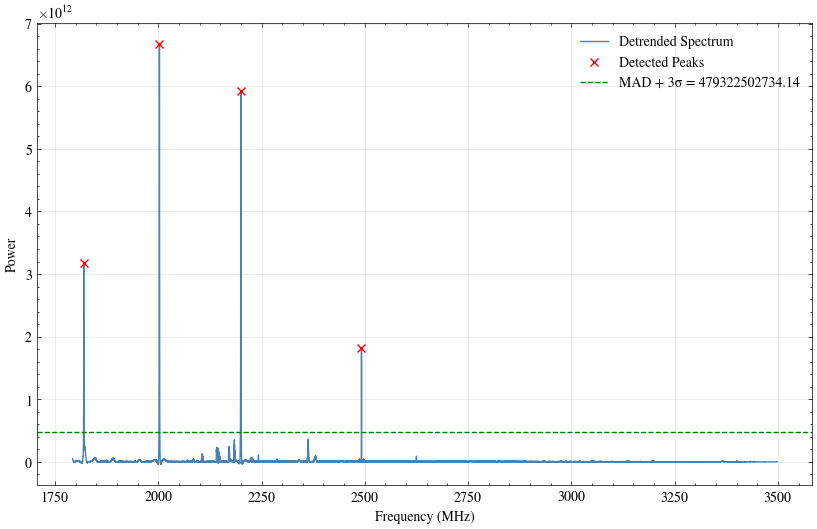

In [10]:
plt.figure(figsize=(10, 6))
plt.plot(frequency_mhz, spectrum_corrected, label='Detrended Spectrum', color='steelblue')
plt.plot(frequency_mhz[peaks], spectrum_corrected[peaks], 'rx', label='Detected Peaks', markersize=6)
plt.axhline(threshold_high, color='green', linestyle='--', label=f'MAD + 3σ = {threshold_high:.2f}')
plt.xlabel("Frequency (MHz)")
plt.ylabel("Power")
plt.legend(loc="upper right")
plt.grid(alpha=0.3)


In [11]:
# define the FWHM

widths_idx, width_heights, left_ips, right_ips = peak_widths(
    spectrum_corrected, peaks, rel_height=0.5)

# frequency resolution
freq_resolution = frequency_mhz[1] - frequency_mhz[0]
fwhm_freq = widths_idx * freq_resolution



for i, pk in enumerate(peaks):
    print(f"Peak at {frequency_mhz[pk]:.4f} MHz | FWHM = {fwhm_freq[i]:.4f} MHz "
          f"| half-max level = {width_heights[i]:.4e}")

Peak at 1819.6278 MHz | FWHM = 0.4368 MHz | half-max level = 1.5757e+12
Peak at 2002.7828 MHz | FWHM = 0.6259 MHz | half-max level = 3.3197e+12
Peak at 2199.9302 MHz | FWHM = 0.6552 MHz | half-max level = 2.9460e+12
Peak at 2492.0063 MHz | FWHM = 0.0353 MHz | half-max level = 9.0465e+11


Peak frequencies (MHz): [1819.62776184 2002.78282166 2199.93019104 2492.00630188]
FWHM (MHz): [0.43675853 0.62590337 0.65517774 0.03528455]
FWHM (kHz): [436.75853089 625.90336523 655.17773563  35.28454761]


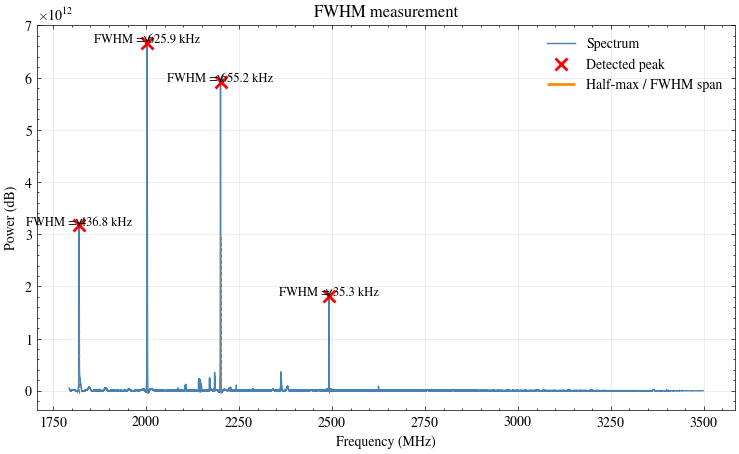

In [12]:

 
# Convert fractional index crossings to frequency values
idx_axis = np.arange(len(frequency_mhz))
left_freq = np.interp(left_ips, idx_axis, frequency_mhz)
right_freq = np.interp(right_ips, idx_axis, frequency_mhz)
 
# ---------------------------------------------------------------
# 4. Plot
# ---------------------------------------------------------------
fig, ax = plt.subplots(figsize=(9, 5))
 
ax.plot(frequency_mhz, spectrum_corrected, color="steelblue", lw=1, label="Spectrum")
ax.plot(frequency_mhz[peaks], spectrum_corrected[peaks], "rx", ms=8, mew=2, label="Detected peak")
 
# Half-max horizontal lines (crossing level) and FWHM span
for i in range(len(peaks)):
    ax.hlines(
        width_heights[i], left_freq[i], right_freq[i],
        color="darkorange", lw=2,
        label="Half-max / FWHM span" if i == 0 else None
    )
    # Vertical guides marking the crossing points
    ax.vlines(
        [left_freq[i], right_freq[i]],
        ymin=spectrum_corrected.min(), ymax=width_heights[i],
        color="gray", linestyle="--", lw=0.8
    )
    # Annotate FWHM value
    ax.annotate(
        f"FWHM = {fwhm_freq[i]*1e3:.1f} kHz",
        xy=(frequency_mhz[peaks[i]], spectrum_corrected[peaks[i]]),
        xytext=(frequency_mhz[peaks[i]], spectrum_corrected[peaks[i]] + 0.4),
        ha="center", fontsize=9,
        arrowprops=dict(arrowstyle="->", color="black", lw=0.8)
    )
 
ax.set_xlabel("Frequency (MHz)")
ax.set_ylabel("Power (dB)")
ax.set_title("FWHM measurement")
ax.legend(loc="upper right")
ax.grid(alpha=0.3)
 
# fig.tight_layout()
print("Peak frequencies (MHz):", frequency_mhz[peaks])
print("FWHM (MHz):", fwhm_freq)
print("FWHM (kHz):", fwhm_freq * 1e3)

In [13]:
peaks

array([ 1008,  7867, 15250, 26188])

/home/chavango/anaconda3/envs/SKAMPIDATA/lib/python3.11/site-packages/IPython/core/pylabtools.py:152: UserWarning: Glyph 7525 (\N{LATIN SUBSCRIPT SMALL LETTER V}) missing from font(s) STIXGeneral.
  fig.canvas.print_figure(bytes_io, **kw)


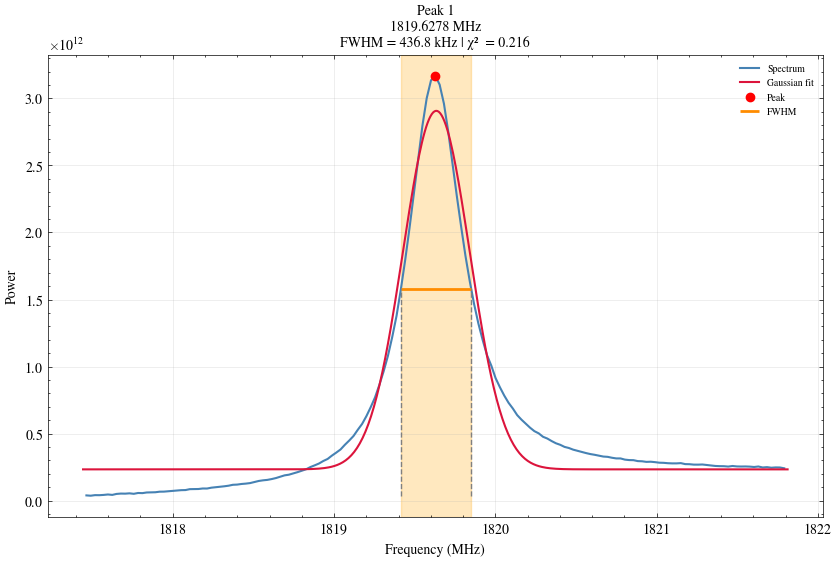

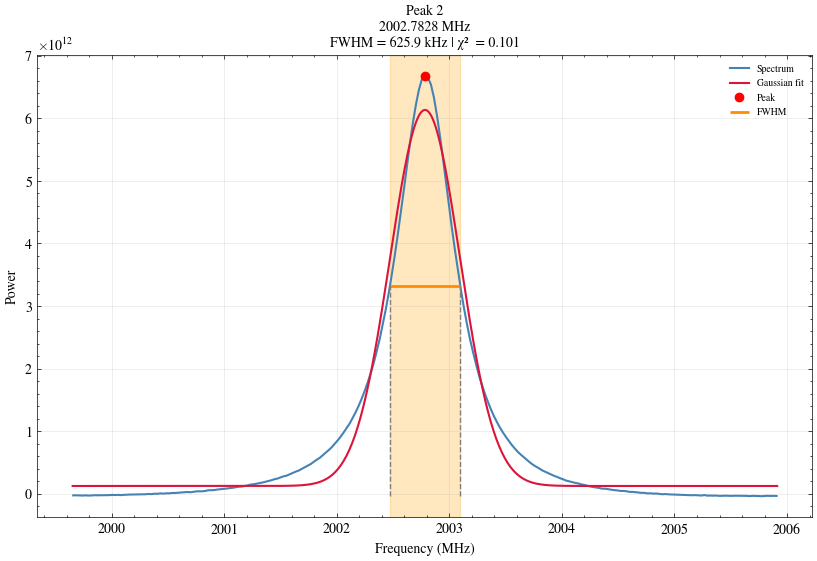

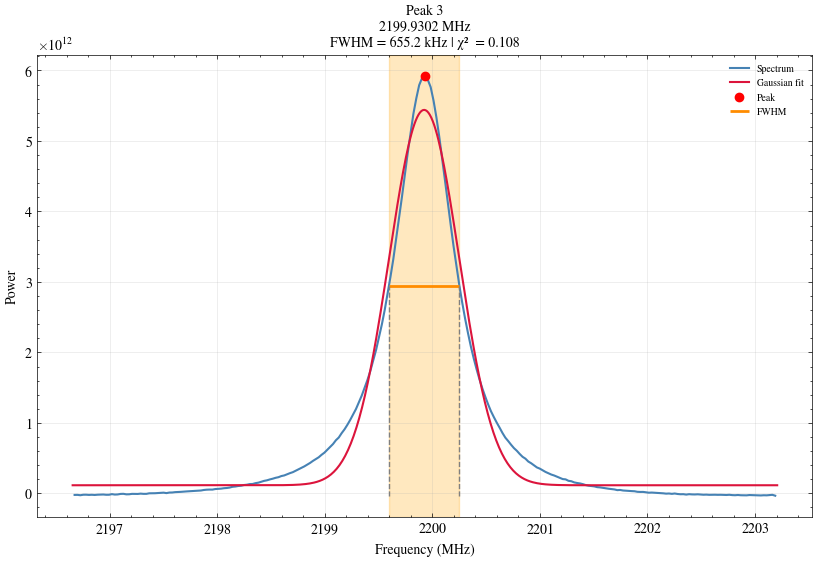

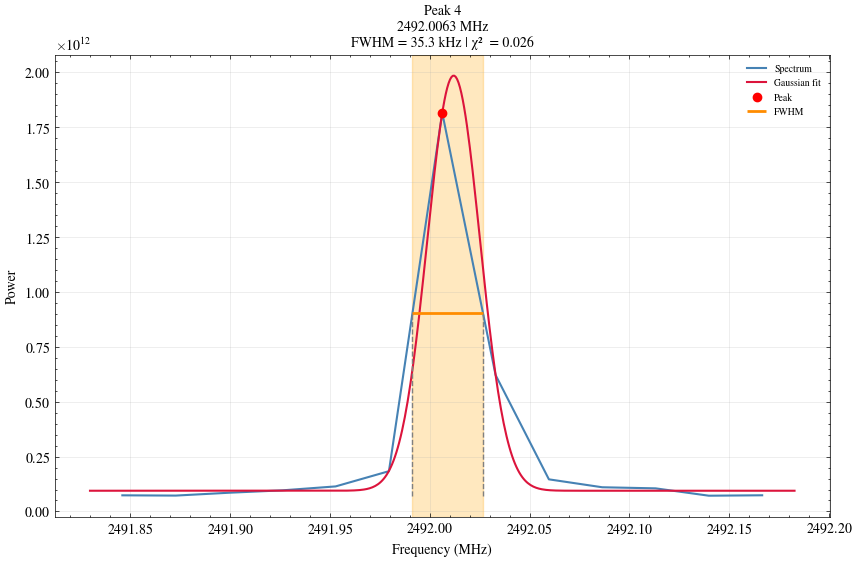

In [14]:

high_peak_details = []


# ---------------------------------------------------------------
# Parameters
# ---------------------------------------------------------------
window = 5  # Number of FWHMs to display on each side of the peak

gaussian_fit_results = []  # collect fit params + chi-squared per peak

external_noise_std = None

for i, peak in enumerate(peaks):


    centre = frequency_mhz[peak]

    # Zoom window proportional to the measured FWHM
    x_min = centre - window * fwhm_freq[i]
    x_max = centre + window * fwhm_freq[i]

    mask = (frequency_mhz >= x_min) & (frequency_mhz <= x_max)

    x_data = frequency_mhz[mask]
    y_data = spectrum_corrected[mask]

    # -------------------------------------------------------
    # Estimate per-point noise (sigma) for chi-squared
    # -------------------------------------------------------
    if external_noise_std is not None:
        if np.isscalar(external_noise_std):
            noise_std = external_noise_std
        else:
            noise_std = np.median(np.asarray(external_noise_std)[mask])
    else:
        off_peak_mask = (x_data < left_freq[i]) | (x_data > right_freq[i])
        if np.sum(off_peak_mask) > 5:
            noise_std = np.std(y_data[off_peak_mask])
        else:
            noise_std = np.std(y_data)

    if noise_std == 0:
        noise_std = 1e-6  # guard against a zero-noise edge case

    # -------------------------------------------------------
    # Gaussian fit
    # -------------------------------------------------------
    sigma_guess = fwhm_freq[i] / 2.3548
    amp_guess = spectrum_corrected[peak] #- np.median(y_data)
    offset_guess = np.median(y_data)

    p0 = [amp_guess, centre, sigma_guess, offset_guess]

    try:
        popt, pcov = curve_fit(
            gaussian, x_data, y_data, p0=p0,
            sigma=noise_std, absolute_sigma=True, maxfev=10000
            )
        y_fit_at_data = gaussian(x_data, *popt)
        chi2, chi2_reduced = chi_squared(
            y_data, y_fit_at_data, noise_std, n_params=4
        )

        x_smooth = np.linspace(x_min, x_max, 500)
        y_smooth = gaussian(x_smooth, *popt)

        fit_success = True
    except RuntimeError:
        popt = [np.nan] * 4
        chi2, chi2_reduced = np.nan, np.nan
        x_smooth, y_smooth = None, None
        fit_success = False

    gaussian_fit_results.append({
        "peak_freq_mhz": centre,
        "amplitude": popt[0],
        "fitted_centre_mhz": popt[1],
        "sigma_mhz": popt[2],
        "offset": popt[3],
        "noise_std": noise_std,
        "chi_squared": chi2,
        "reduced_chi_squared": chi2_reduced,
        "fit_success": fit_success,
    })


    # determine the OBW
    total_power = np.sum(y_data)
    cumulative_power = np.cumsum(y_data)
    lower_bound_idx = np.searchsorted(cumulative_power, 0.05 * total_power)
    upper_bound_idx = np.searchsorted(cumulative_power, 0.95 * total_power)
    obw_lower_freq = x_data[lower_bound_idx]
    obw_upper_freq = x_data[upper_bound_idx] 

    #occupaied bandwidth
    occupied_bandwidth = obw_upper_freq - obw_lower_freq

    # ratio obw to fwhm
    obw_to_fwhm_ratio = occupied_bandwidth / fwhm_freq[i]
      

    # create a data frame to store the results
    
    high_peak_details.append({
    
    "detected_frequency_[MHz]": centre,
    "fitted_frequency_[MHz]": popt[1],
    "fitted_amplitude_[dB]": popt[0],
    "detrended_signal_[dB]": spectrum_corrected[peak],
    "occupied_bandwidth_[MHz]": occupied_bandwidth,
    "fwhm_[MHz]": fwhm_freq[i],
    "obw_to_fwhm_ratio": obw_to_fwhm_ratio
    })


    plt.figure(figsize=(10, 6))
    # -------------------------------------------------------
    # Spectrum
    # -------------------------------------------------------
    plt.plot(x_data, y_data, color="steelblue", lw=1.5, label="Spectrum")

    if fit_success:
        plt.plot(x_smooth, y_smooth, color="crimson", lw=1.5,
                 linestyle="-", label="Gaussian fit")

    plt.plot(centre, spectrum_corrected[peak], 'ro', ms=6, label='Peak')

    plt.hlines(width_heights[i], left_freq[i], right_freq[i],
              color='darkorange', lw=2, label='FWHM')

    plt.vlines([left_freq[i], right_freq[i]],
              ymin=y_data.min(), ymax=width_heights[i],
              color='gray', linestyle='--')

    plt.axvspan(left_freq[i], right_freq[i], color='orange', alpha=0.25)

    chi2_str = f"{chi2_reduced:.3f}" if fit_success else "fit failed"
    plt.title(
        f"Peak {i+1}\n"
        f"{centre:.4f} MHz\n"
        f"FWHM = {fwhm_freq[i]*1000:.1f} kHz | \u03c7\u00b2\u1d65 = {chi2_str}",
        fontsize=10
    )

    plt.xlabel("Frequency (MHz)")
    plt.ylabel("Power")
    plt.grid(alpha=0.3)
    plt.legend(fontsize=7, loc="upper right")


# # Remove empty axes
# fig.tight_layout()

# if to_save:
#         # create full path
#     full_path = os.path.join(dirname, scan_name)
#     # create the directory if they don't exist
#     os.makedirs(full_path, exist_ok=True)

#     fig.savefig(
#         os.path.join(full_path, f'{scan_name}_high_peak_gaussian_fits.png'),
#         dpi=300,
#         bbox_inches="tight",
#         facecolor="white"
#     )

#     fig.savefig(
#         os.path.join(full_path, f'{scan_name}_high_peak_gaussian_fits.pdf'),
#         bbox_inches="tight",
#         facecolor="white"
#     )


plt.show()

# gaussian_fit_results now holds, per peak:
#   fitted amplitude, centre, sigma, offset, noise_std,
#   chi_squared, and reduced_chi_squared

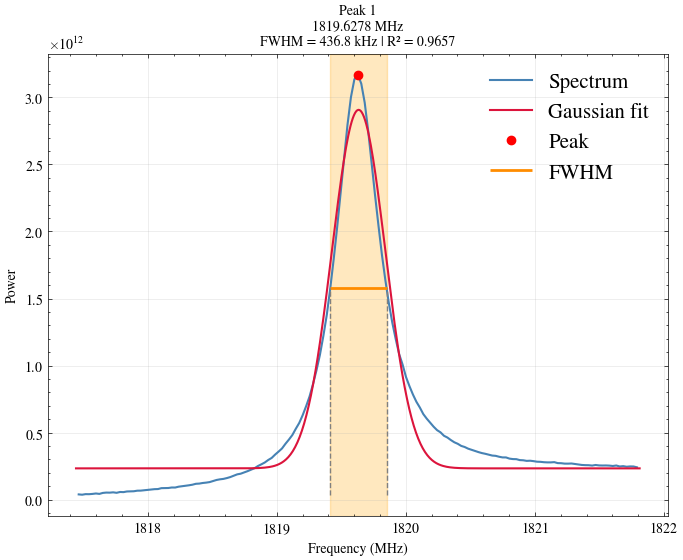

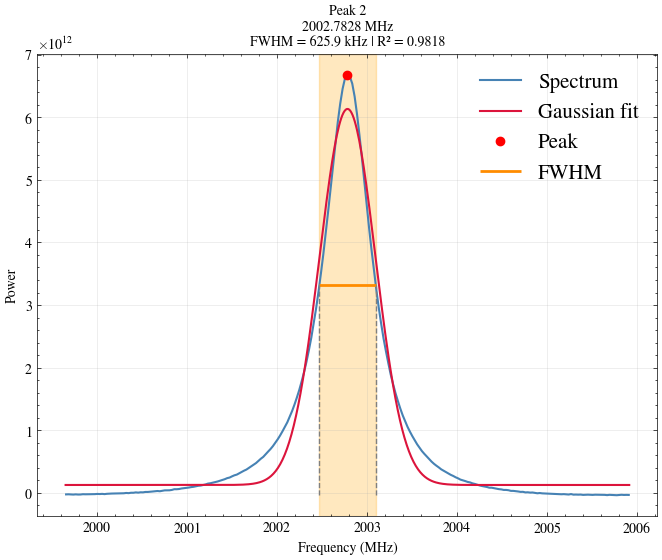

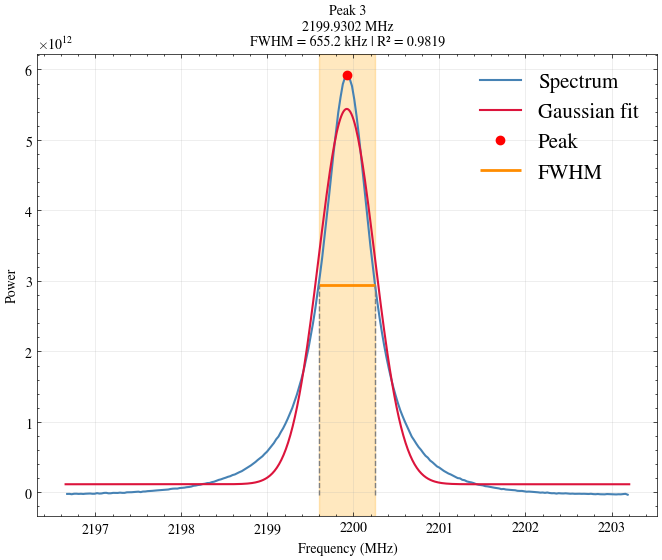

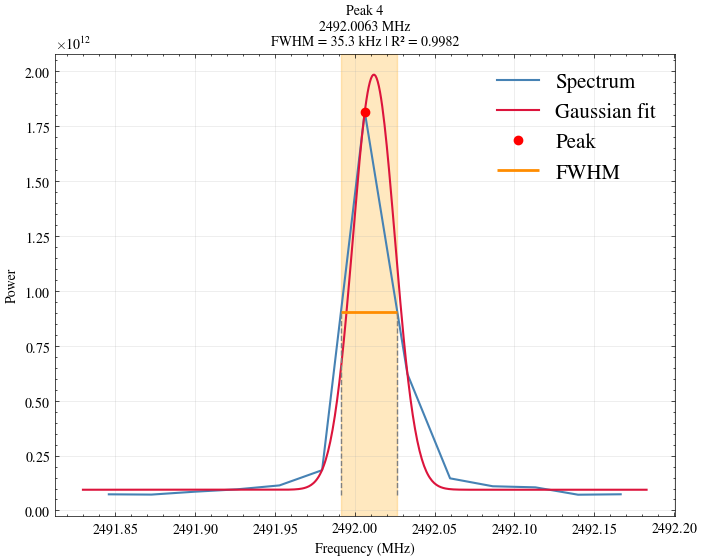

In [15]:

# # ---------------------------------------------------------------
# # Gaussian model with a constant offset (baseline)
# # ---------------------------------------------------------------
# def gaussian(x, amplitude, centre, sigma, offset):
#     return offset + amplitude * np.exp(-0.5 * ((x - centre) / sigma) ** 2)
 
 
def r_squared(y_data, y_fit):
    """Coefficient of determination R^2."""
    ss_res = np.sum((y_data - y_fit) ** 2)
    ss_tot = np.sum((y_data - np.mean(y_data)) ** 2)
    return 1 - ss_res / ss_tot
 

 
# ---------------------------------------------------------------
# Parameters
# ---------------------------------------------------------------
window = 5  # Number of FWHMs to display on each side of the peak

gaussian_fit_results = []  # collect fit params + R^2 per peak
 
for i, peak in enumerate(peaks):
  
    centre = frequency_mhz[peak]
 
    # Zoom window proportional to the measured FWHM
    x_min = centre - window * fwhm_freq[i]
    x_max = centre + window * fwhm_freq[i]
 
    mask = (frequency_mhz >= x_min) & (frequency_mhz <= x_max)
 
    x_data = frequency_mhz[mask]
    y_data = spectrum_corrected[mask]
 
    # -------------------------------------------------------
    # Gaussian fit
    # -------------------------------------------------------
    # FWHM = 2*sqrt(2*ln2)*sigma  =>  sigma = FWHM / 2.3548
    sigma_guess = fwhm_freq[i] / 2.3548
    amp_guess = spectrum_corrected[peak] - np.median(y_data)
    offset_guess = np.median(y_data)
 
    p0 = [amp_guess, centre, sigma_guess, offset_guess]
 
    try:
        popt, pcov = curve_fit(gaussian, x_data, y_data, p0=p0, maxfev=10000)
        y_fit_at_data = gaussian(x_data, *popt)
        r2 = r_squared(y_data, y_fit_at_data)
 
        # Smooth curve for plotting
        x_smooth = np.linspace(x_min, x_max, 500)
        y_smooth = gaussian(x_smooth, *popt)
 
        fit_success = True
    except RuntimeError:
        popt = [np.nan] * 4
        r2 = np.nan
        x_smooth, y_smooth = None, None
        fit_success = False
 
    gaussian_fit_results.append({
        "peak_freq_mhz": f'{centre:.2f}',
        "amplitude": popt[0],
        "fitted_centre_mhz": f'{popt[1]:.2f}',
        "sigma_mhz": f'{popt[2]:.2f}',
        "offset": f'{popt[3]:.2f}',
        "r_squared": f'{r2:.2f}',
    })

    plt.figure(figsize=(8, 6))
    # -------------------------------------------------------
    # Spectrum
    # -------------------------------------------------------
    plt.plot(
        x_data,
        y_data,
        color="steelblue",
        lw=1.5,
        label="Spectrum"
    )
 
    # Gaussian fit overlay
    if fit_success:
        plt.plot(
            x_smooth,
            y_smooth,
            color="crimson",
            lw=1.5,
            linestyle="-",
            label="Gaussian fit"
        )
 
    # Peak marker
    plt.plot(
        centre,
        spectrum_corrected[peak],
        'ro',
        ms=6,
        label='Peak'
    )
 
    # FWHM line
    plt.hlines(
        width_heights[i],
        left_freq[i],
        right_freq[i],
        color='darkorange',
        lw=2,
        label='FWHM'
    )
 
    # Crossing points
    plt.vlines(
        [left_freq[i], right_freq[i]],
        ymin=y_data.min(),
        ymax=width_heights[i],
        color='gray',
        linestyle='--'
    )
 
    # Shade the FWHM
    plt.axvspan(
        left_freq[i],
        right_freq[i],
        color='orange',
        alpha=0.25
    )
 
    r2_str = f"{r2:.4f}" if fit_success else "fit failed"
    plt.title(
        f"Peak {i+1}\n"
        f"{centre:.4f} MHz\n"
        f"FWHM = {fwhm_freq[i]*1000:.1f} kHz | R\u00b2 = {r2_str}",
        fontsize=10
    )
 
    plt.xlabel("Frequency (MHz)")
    plt.ylabel("Power")
    plt.grid(alpha=0.3)
    plt.legend(fontsize=15, loc="upper right")



# # Remove empty axes
# fig.tight_layout()

# if to_save:
#     fig.savefig(
#         "gaussian_peak_fits.png",
#         dpi=300,
#         bbox_inches="tight",
#         facecolor="white"
#     )
 
plt.show()
 

In [16]:
gaussian_fit_results

[{'peak_freq_mhz': '1819.63',
  'amplitude': np.float64(2673449440502.6123),
  'fitted_centre_mhz': '1819.63',
  'sigma_mhz': '0.21',
  'offset': '233646821444.12',
  'r_squared': '0.97'},
 {'peak_freq_mhz': '2002.78',
  'amplitude': np.float64(6005589201490.257),
  'fitted_centre_mhz': '2002.78',
  'sigma_mhz': '0.31',
  'offset': '126385140437.30',
  'r_squared': '0.98'},
 {'peak_freq_mhz': '2199.93',
  'amplitude': np.float64(5325144654898.001),
  'fitted_centre_mhz': '2199.92',
  'sigma_mhz': '0.33',
  'offset': '115450817595.30',
  'r_squared': '0.98'},
 {'peak_freq_mhz': '2492.01',
  'amplitude': np.float64(1891362092197.5347),
  'fitted_centre_mhz': '2492.01',
  'sigma_mhz': '0.01',
  'offset': '94413166641.92',
  'r_squared': '1.00'}]

In [17]:
df_gauussian_fit = pd.DataFrame(gaussian_fit_results)
df_gauussian_fit

,peak_freq_mhz,amplitude,fitted_centre_mhz,sigma_mhz,offset,r_squared
0,1819.63,2.673449e+12,1819.63,0.21,233646821444.12,0.97
1,2002.78,6.005589e+12,2002.78,0.31,126385140437.30,0.98
2,2199.93,5.325145e+12,2199.92,0.33,115450817595.30,0.98
3,2492.01,1.891362e+12,2492.01,0.01,94413166641.92,1.00



Outlier 1:
  Peak Frequency : 1819.6278 GHz
  Peak Power     : 3168865687617.8301 dB
  Start Frequency: 1816.3700 GHz
  End Frequency  : 1826.9978 GHz
  Bandwidth      : 10.6277 GHz
  Corrupted Ch.  : 398 channels

Outlier 2:
  Peak Frequency : 2002.7828 GHz
  Peak Power     : 6670185580899.4863 dB
  Start Frequency: 2000.3529 GHz
  End Frequency  : 2004.8923 GHz
  Bandwidth      : 4.5395 GHz
  Corrupted Ch.  : 170 channels

Outlier 3:
  Peak Frequency : 2199.9302 GHz
  Peak Power     : 5925452067040.1094 dB
  Start Frequency: 2197.3400 GHz
  End Frequency  : 2202.1732 GHz
  Bandwidth      : 4.8332 GHz
  Corrupted Ch.  : 181 channels

Outlier 4:
  Peak Frequency : 2492.0063 GHz
  Peak Power     : 1816093130718.0786 dB
  Start Frequency: 2490.9649 GHz
  End Frequency  : 2493.1278 GHz
  Bandwidth      : 2.1629 GHz
  Corrupted Ch.  : 81 channels


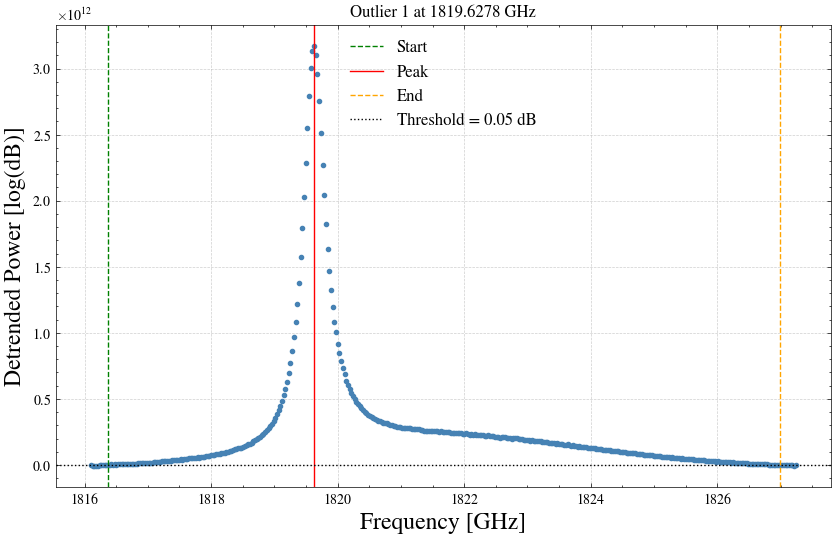

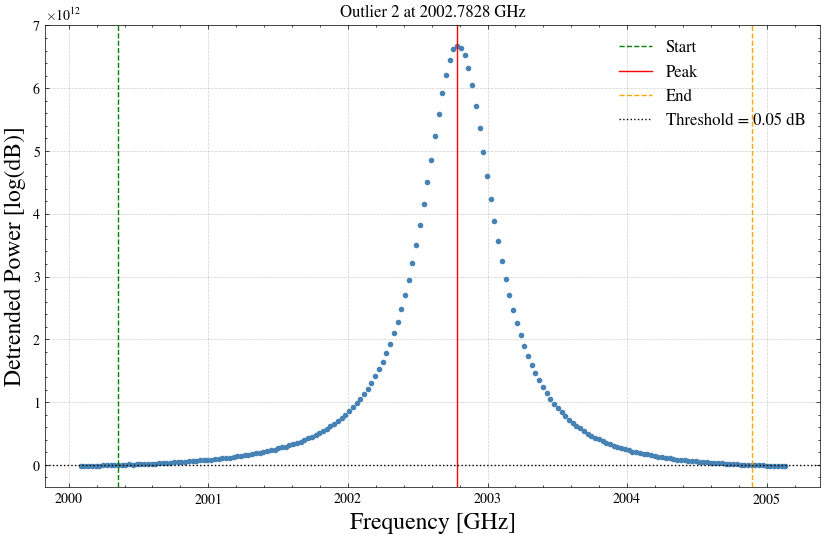

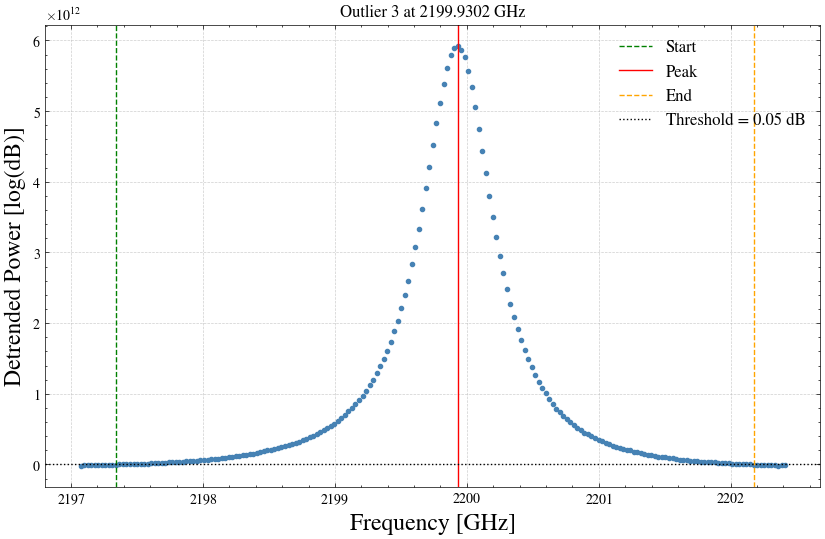

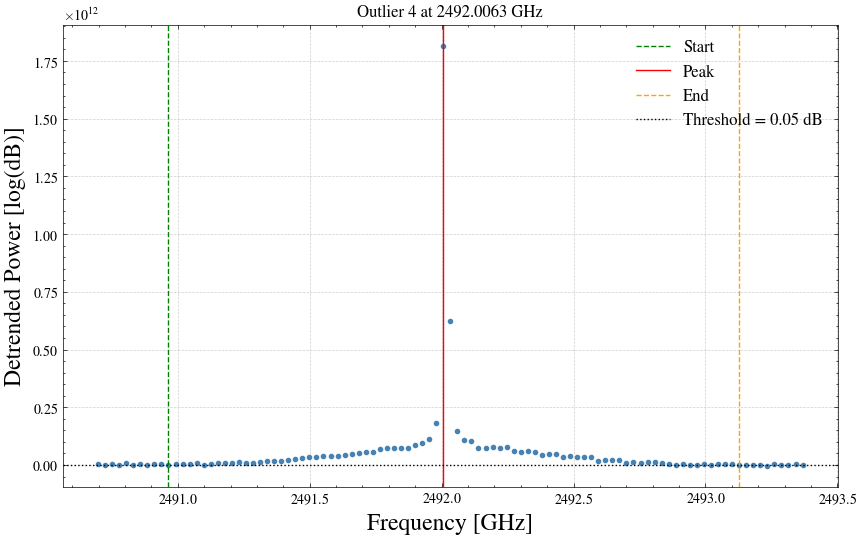

In [18]:
# Evaluate the low level peaks
results_outliers = quantify_all_outliers(frequency_mhz, spectrum_corrected, frequency_mhz[peaks], plot=True)


Peaks detected at [14:58:44]: ['2106.1497', '2142.0918', '2145.8836', '2170.3434', '2184.1488', '2242.4679', '2362.8979', '2380.0945', '2624.9866'] MHz


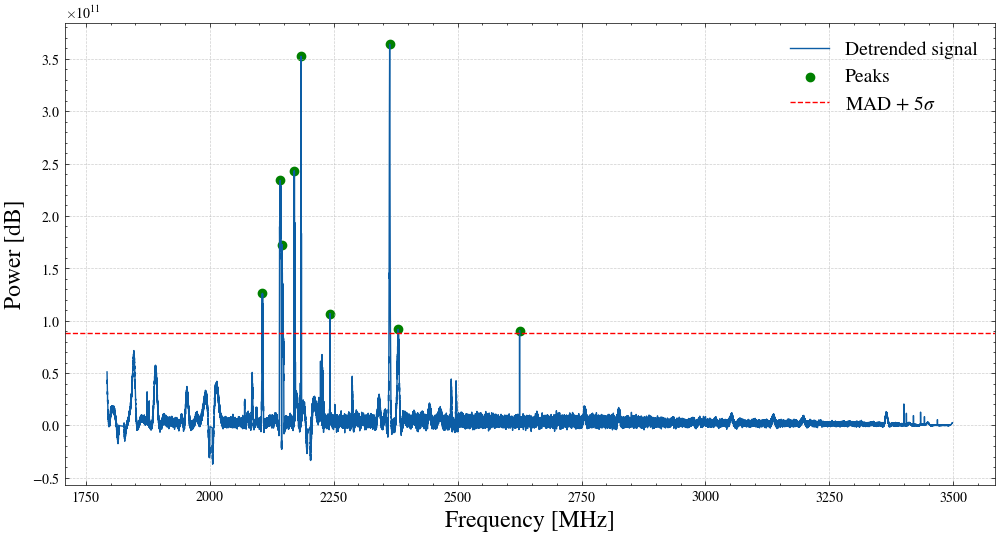

In [19]:

mask_high = build_rfi_mask(frequency_mhz, results_outliers)

# make a copy of the spectrum
mask_signal = spectrum_corrected.copy()

# replace the flagged channels with NaN
mask_signal = mask_signal[~mask_high]
mask_frequency = frequency_mhz[~mask_high]

 
sigma_value_low = 5 
threshold = MAD(mask_signal) + sigma_value_low * np.std(mask_signal)

peaks_low, properties = find_peaks(
    mask_signal,
    height=threshold,
    prominence=0.3,
    distance=110
)

# 5) Plot
plt.figure(figsize=(12, 6))
plt.plot(mask_frequency, mask_signal, label='Detrended signal')
plt.scatter(mask_frequency[peaks_low], mask_signal[peaks_low], 
            color='green', label='Peaks')

plt.axhline(y=threshold, color='red', linestyle='--',
            label=f'MAD + {sigma_value_low}$σ$')

plt.xlabel('Frequency [MHz]', fontsize=17)
plt.ylabel('Power [dB]', fontsize=17)
plt.grid(True, linestyle='--', alpha=0.6)
plt.legend(fontsize=14)

#define the yticks size the same for all the plots
# yticks=np.arange(-1, 5, 1)
# plt.yticks(yticks)


formatted_freqs = [f"{f:.4f}" for f in mask_frequency[peaks_low]]
print(f"Peaks detected at [{time_utc[i].strftime('%H:%M:%S')}]: {formatted_freqs} MHz")

# plt.savefig('/home/chavango/Master/SKAMPI_DATA/work_with_the_dataset/Detrending/SKAMPI_RFI_PIPELINE/low_level_peak_plot.png', dpi=300, bbox_inches='tight')
# plt.savefig('/home/chavango/Master/SKAMPI_DATA/work_with_the_dataset/Detrending/SKAMPI_RFI_PIPELINE/low_level_peak_plot.pdf', dpi=300, bbox_inches='tight')


plt.show()
